# Weekly project
This weeks weekly project is a continuation of last weeks exercises.

You are to make a handwritten number classifier. Where we will be using the [mnist dataset](https://en.wikipedia.org/wiki/MNIST_database).

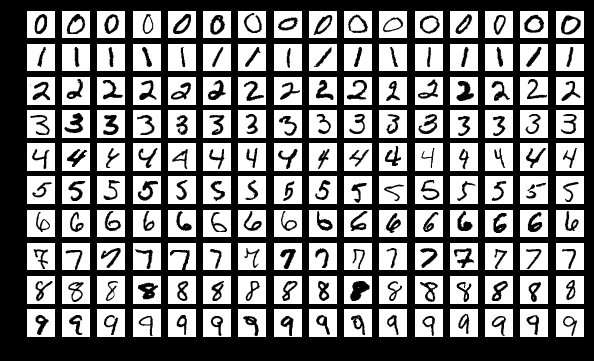

**Create a program that given an image from the mnist dataset.**
- You are free to use any algorithm you want to achieve this.
- It should be able to given a number classify what number it is.
- Accuracy should at least be 80%

If you decide to use a svm make sure you also use dimensionality reduction. SVM of the full mnist dataset will take around 4-8 hours depending on your pc.



**Challange:**
- Try to reach 98% accuracy.
- Try to classify faces with the labeled wild faces dataset [lwf](http://vis-www.cs.umass.edu/lfw/)
```{Python}
from sklearn.datasets import fetch_lfw_people
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
```

In [2]:
import math

import matplotlib.pyplot as plt
import numpy as np
import time
import datetime as dt
from sklearn.decomposition import PCA
from sklearn import datasets, svm, metrics
from sklearn.datasets import fetch_openml
import sklearn as sk
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
import pandas as pd
import copy

import ssl
ssl._create_default_https_context = ssl._create_unverified_context
mnist = fetch_openml('mnist_784', version=1)

images = mnist.data.to_numpy()
targets = mnist.target.to_numpy()

print(images.shape)
print(targets.shape)

(70000, 784)
(70000,)


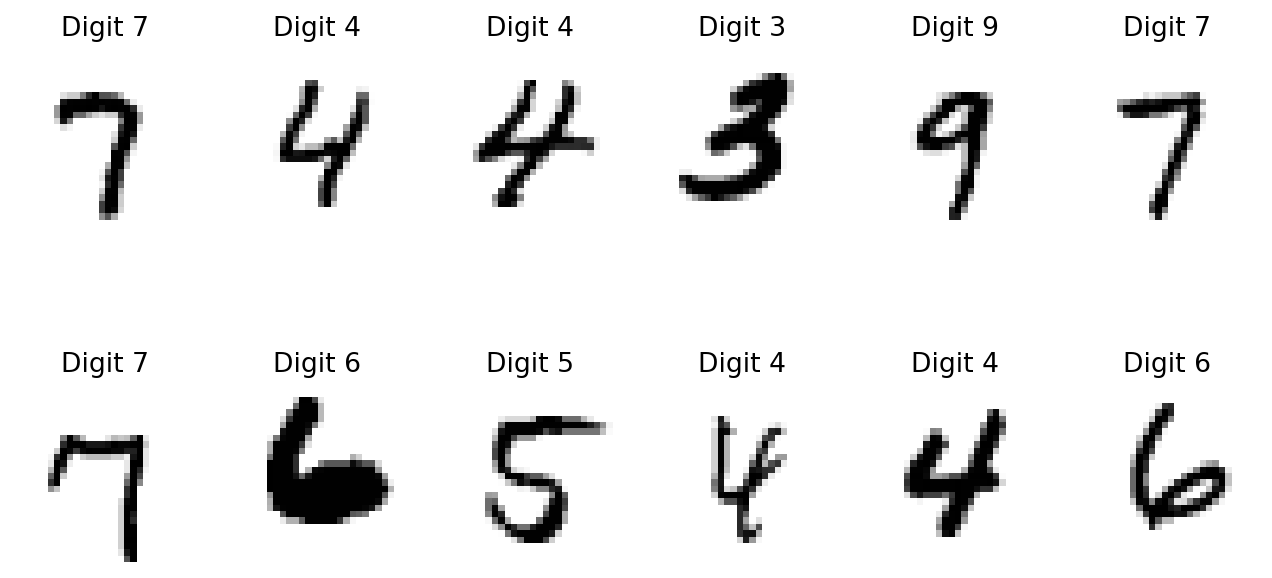

In [3]:
def show_some_digits(images, targets, sample_size=24, title_text='Digit {}' ):
    '''
    Visualize random digits in a grid plot
    images - array of flatten gidigs [:,784]
    targets - final labels
    '''
    nsamples=sample_size
    rand_idx = np.random.choice(images.shape[0], nsamples)
    images_and_labels = list(zip(images[rand_idx], targets[rand_idx]))


    img = plt.figure(1, figsize=(10, 5), dpi=160)
    for index, (image, label) in enumerate(images_and_labels):
        plt.subplot(math.ceil(nsamples/6.0), 6, index + 1)
        plt.axis('off')
        #each image is flat, we have to reshape to 2D array 28x28-784
        plt.imshow(image.reshape(28,28), cmap=plt.cm.gray_r, interpolation='nearest')
        plt.title(title_text.format(label))
    plt.show()

# draw 12 images along with their labels
show_some_digits(images, targets, 12)

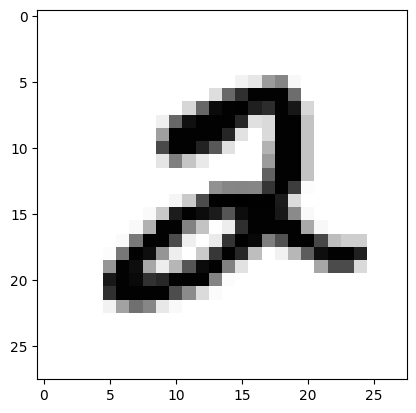

In [4]:
plt.imshow(images[5, :].reshape(28, 28), cmap = 'gray_r')

## PCA and SVC

In [5]:
X = copy.deepcopy(images)

X_scaled = StandardScaler().fit_transform(X)

87


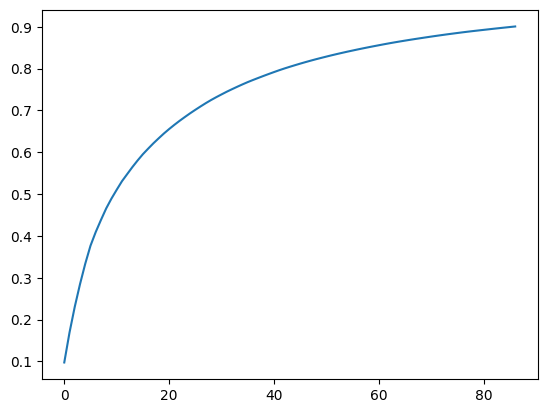

In [8]:
values = np.array([])
for i in range(1, 100):

    pca = PCA(n_components = i)
    principalComponents = pca.fit_transform(X)

    #print(pca.explained_variance_ratio_)
    #print(i)
    #print(sum(pca.explained_variance_ratio_))
    
    values = np.append(values, sum(pca.explained_variance_ratio_))

    if sum(pca.explained_variance_ratio_) > 0.9:
        print(i)
        break
plt.plot(np.arange(len(values)), values)

In [20]:
# scaled dataset 20 points for pca
n_pca = 30
pca_scaled = PCA(n_components = n_pca)

princComp_scaled = pca_scaled.fit_transform(X)

n = 0.25
X_train, X_test, y_train, y_test = train_test_split(princComp_scaled, targets, test_size = n, random_state = 42)
X_scaled = StandardScaler().fit_transform(X_train)

clf = sk.svm.LinearSVC(penalty = 'l2', loss = 'squared_hinge', random_state = 0, max_iter = int(10e4))

clf.fit(X_scaled, y_train)

train_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)

print('Train score: ', train_score)
print('Test score: ', test_score)

Train score:  0.7086476190476191
Test score:  0.7101142857142857


In [ ]:
train_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)

print('Train score: ', train_score)
print('Test score: ', test_score)

## CNN


In [1]:
import keras
from keras.utils import to_categorical


I0000 00:00:1793286341.823993   13096 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793286341.875971   13096 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793286344.819885   13096 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
